# DSCI 552 Homework 6

-Name: Shiyi Fan  
-GitHub Username: 1111v1y\
-USC ID: 5554653109

## 1. Tree-Based Methods
### 1.(a)

In [1]:
import pandas as pd
train = pd.read_csv(
    "../data/aps_failure_training_set.csv",
    skiprows = 20,
    na_values = "na"
)
test = pd.read_csv(
    "../data/aps_failure_test_set.csv",
    skiprows = 20,
    na_values = "na"
)

### 1.(b)
#### 1.(b)(i)

In [2]:
import pandas as pd
from sklearn.impute import SimpleImputer
train = pd.read_csv(
    "../data/aps_failure_training_set.csv",
    skiprows = 20,
    na_values = "na"
)
test = pd.read_csv(
    "../data/aps_failure_test_set.csv",
    skiprows = 20,
    na_values = "na"
)
X_train = train.drop(columns = "class")
y_train = train["class"]
X_test = test.drop(columns = "class")
y_test = test["class"]
imputer = SimpleImputer(strategy = "median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns = X_train.columns
)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns = X_test.columns
)

#### 1.(b)(ii)

In [3]:
cv = X_train_imputed.std() / X_train_imputed.mean()

cv_table = cv.to_frame(name = "CV")
cv_table

,CV
aa_000,2.450938
ab_000,10.383494
ac_000,2.310241
ad_000,244.322816
ae_000,24.200137
...,...
ee_007,5.012754
ee_008,3.259079
ee_009,5.691612
ef_000,49.366659


#### 1.(b)(iii)

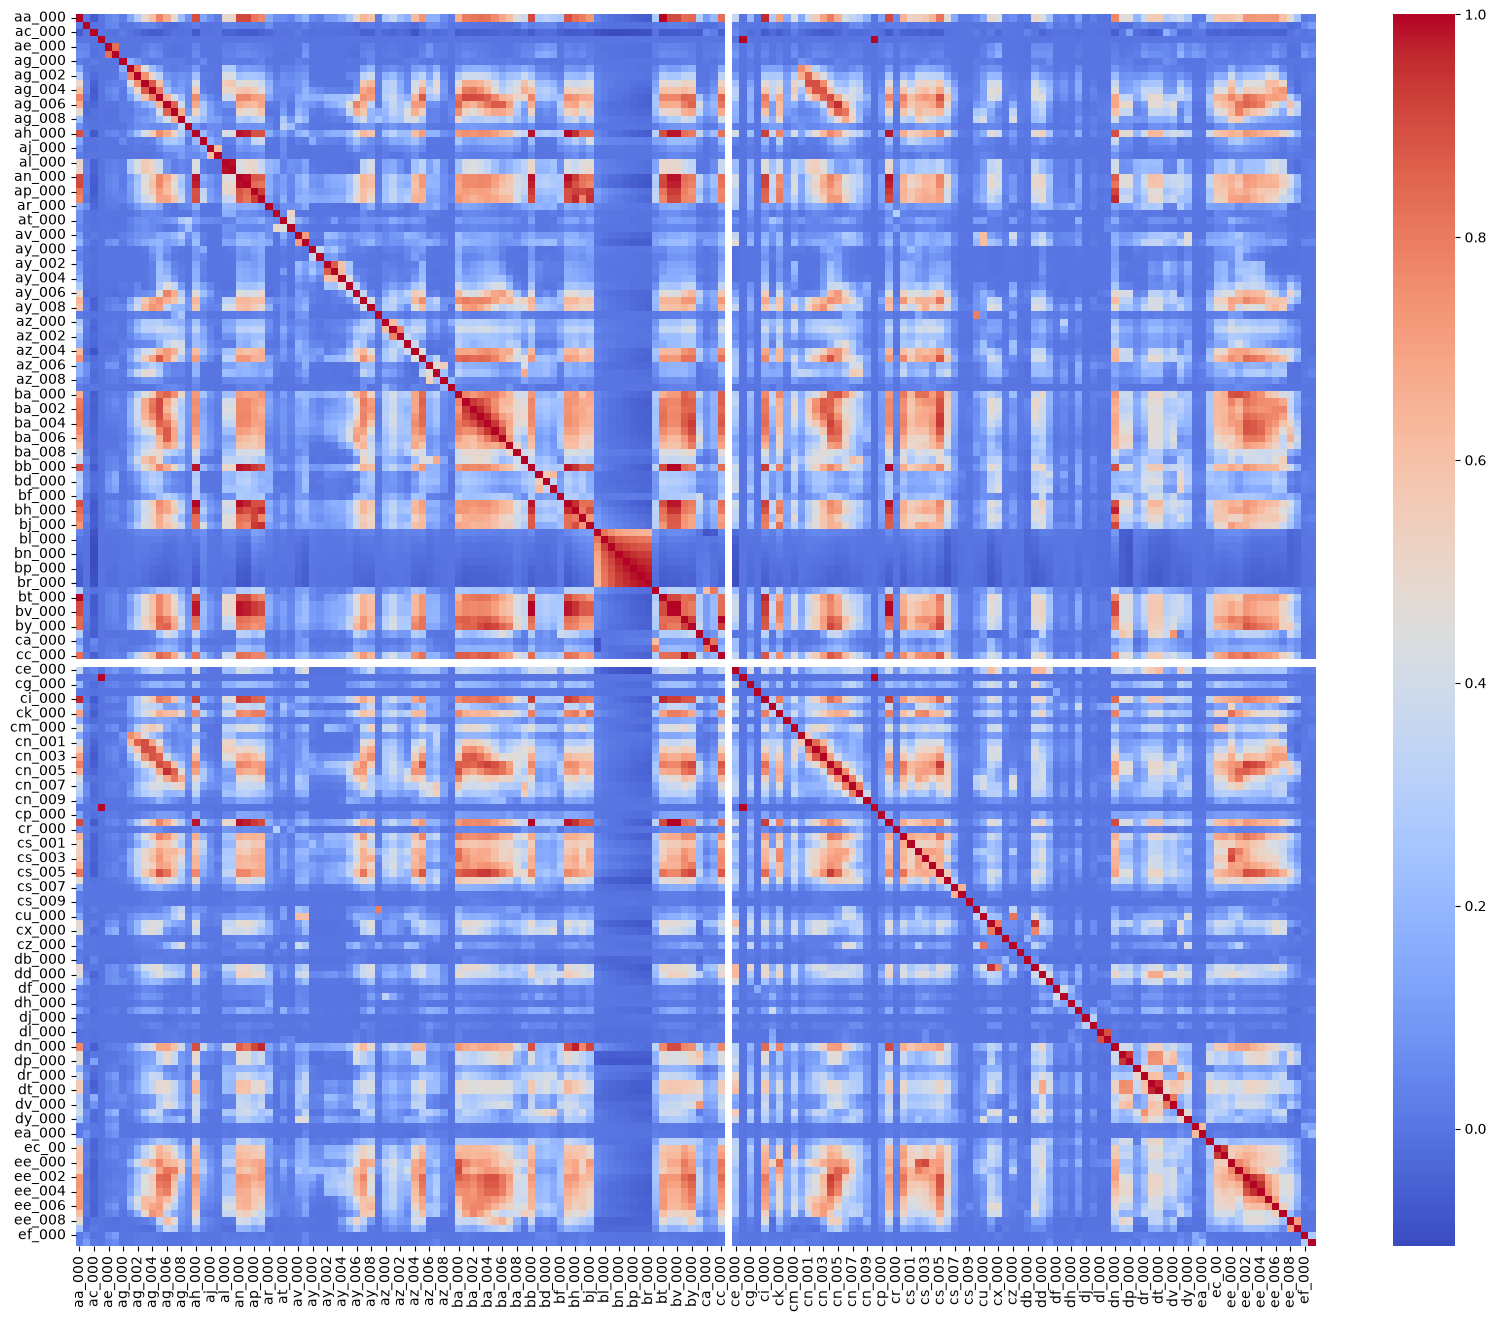

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize = (20, 16))
sns.heatmap(X_train_imputed.corr(), cmap = "coolwarm")
plt.show()

#### 1.(b)(iv)

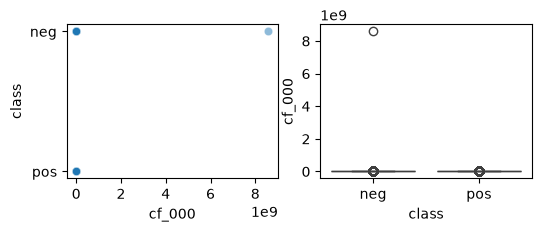

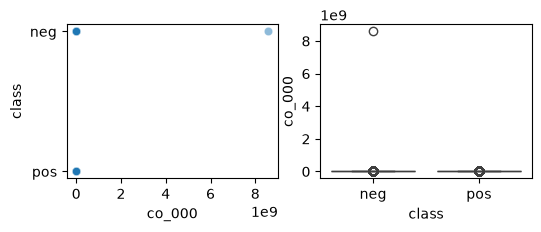

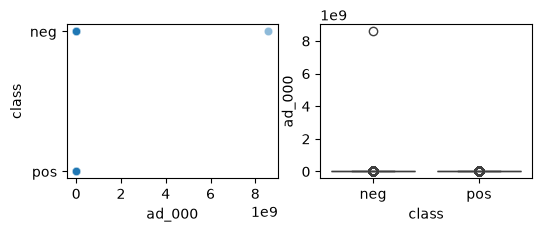

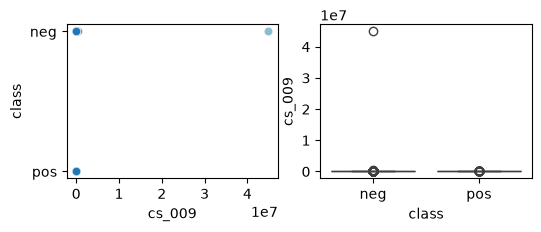

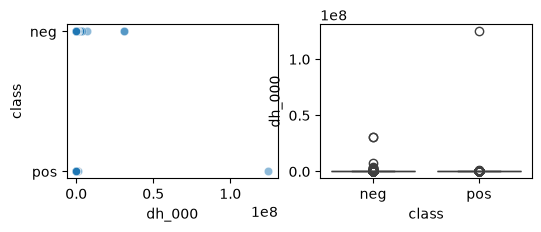

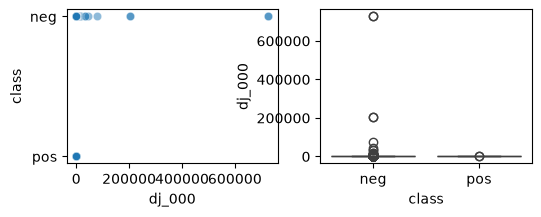

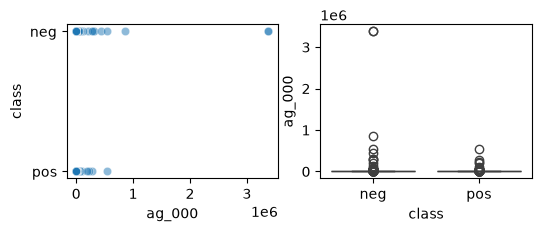

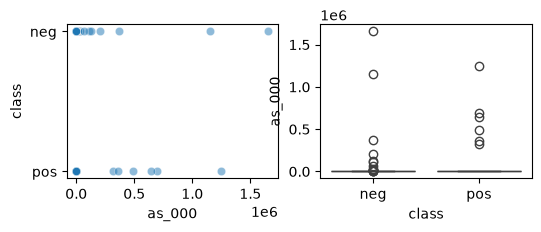

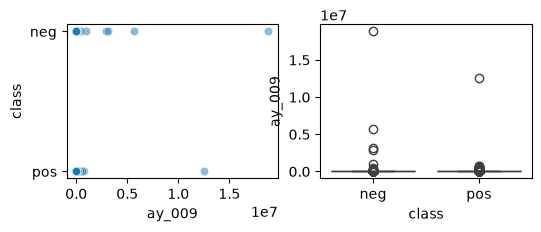

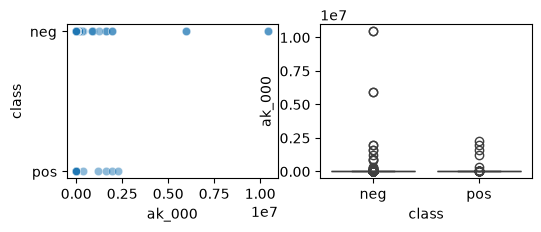

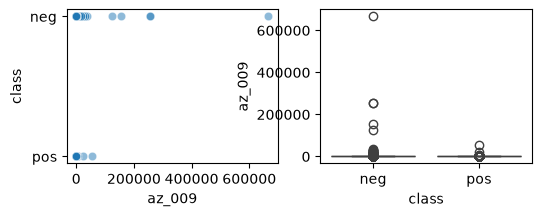

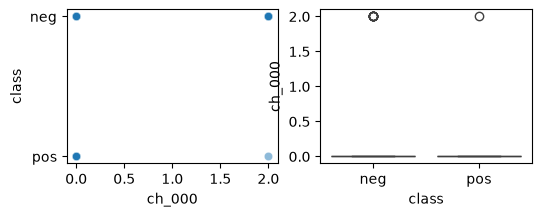

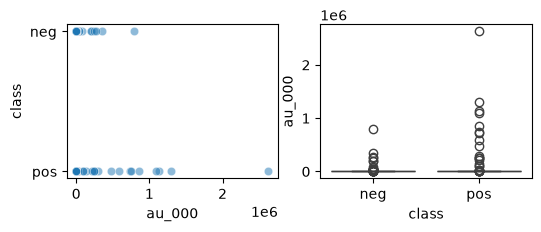

In [5]:
top_features = cv.nlargest(13).index
plot_data = X_train_imputed.copy()
plot_data["class"] = y_train.values
for feature in top_features:
    plt.figure(figsize = (6, 2))
    plt.subplot(1, 2, 1)
    sns.scatterplot(
        data = plot_data,
        x = feature,
        y = "class",
        alpha = 0.5
    )
    plt.subplot(1, 2, 2)
    sns.boxplot(
        data = plot_data,
        x = "class",
        y = feature
    )
    plt.show()

##### -The scatter plots and box plots show that several selected features have highly skewed distributions and extreme outliers.

#### 1.(b)(v)

In [6]:
class_counts = pd.DataFrame({
    "Training Set": y_train.value_counts(),
    "Test Set": y_test.value_counts()
})

class_counts

,Training Set,Test Set
class,,
neg,59000,15625
pos,1000,375


##### -imbalanced

### 1.(c)

Training Confusion Matrix


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,0,1000


Test Confusion Matrix


,Predicted neg,Predicted pos
Actual neg,15606,19
Actual pos,104,271


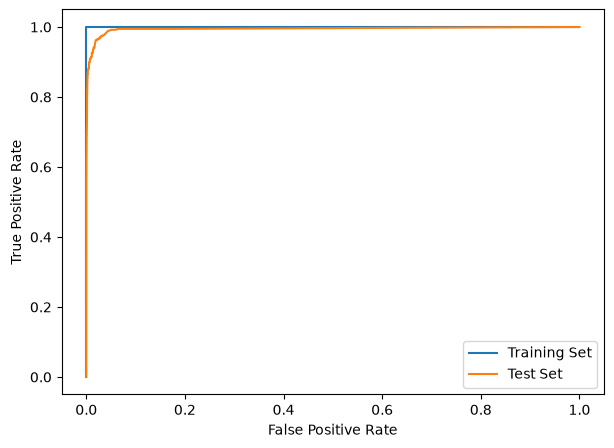

,Training Set,Test Set,OOB Error
AUC,1.0,0.994306,NaN
Misclassification Rate,0.0,0.007687,0.005817


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    accuracy_score
)
rf = RandomForestClassifier(
    n_estimators = 500,
    oob_score = True,
    random_state = 42,
    n_jobs = -1
)
rf.fit(X_train_imputed, y_train)
train_pred = rf.predict(X_train_imputed)
test_pred = rf.predict(X_test_imputed)
pos_index = list(rf.classes_).index("pos")
train_prob = rf.predict_proba(X_train_imputed)[:, pos_index]
test_prob = rf.predict_proba(X_test_imputed)[:, pos_index]
train_cm = confusion_matrix(y_train, train_pred, labels = ["neg", "pos"])
test_cm = confusion_matrix(y_test, test_pred, labels = ["neg", "pos"])
print("Training Confusion Matrix")
display(pd.DataFrame(
    train_cm,
    index = ["Actual neg", "Actual pos"],
    columns = ["Predicted neg", "Predicted pos"]
))
print("Test Confusion Matrix")
display(pd.DataFrame(
    test_cm,
    index = ["Actual neg", "Actual pos"],
    columns = ["Predicted neg", "Predicted pos"]
))
train_fpr, train_tpr, _ = roc_curve(y_train, train_prob, pos_label = "pos")
test_fpr, test_tpr, _ = roc_curve(y_test, test_prob, pos_label = "pos")

plt.figure(figsize = (7, 5))
plt.plot(train_fpr, train_tpr, label = "Training Set")
plt.plot(test_fpr, test_tpr, label = "Test Set")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

train_auc = roc_auc_score(y_train, train_prob)
test_auc = roc_auc_score(y_test, test_prob)
train_error = 1 - accuracy_score(y_train, train_pred)
test_error = 1 - accuracy_score(y_test, test_pred)
oob_error = 1 - rf.oob_score_

pd.DataFrame({
    "Training Set": [train_auc, train_error],
    "Test Set": [test_auc, test_error],
    "OOB Error": [None, oob_error]
}, index = ["AUC", "Misclassification Rate"])

### 1.(d)

Training Confusion Matrix


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,0,1000


Test Confusion Matrix


,Predicted neg,Predicted pos
Actual neg,15612,13
Actual pos,158,217


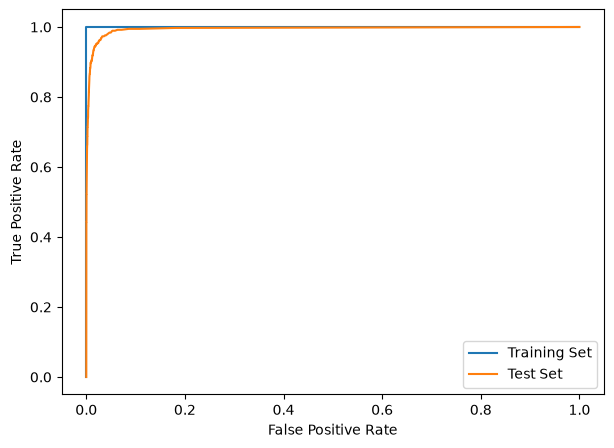

,Training Set,Test Set,OOB Error
AUC,1.0,0.994308,NaN
Misclassification Rate,0.0,0.010687,0.007483


In [8]:
rf_balanced = RandomForestClassifier(
    n_estimators = 500,
    class_weight = "balanced_subsample",
    oob_score = True,
    random_state = 42,
    n_jobs = -1
)
rf_balanced.fit(X_train_imputed, y_train)
train_predb = rf_balanced.predict(X_train_imputed)
test_predb = rf_balanced.predict(X_test_imputed)
pos_index = list(rf_balanced.classes_).index("pos")
train_probb = rf_balanced.predict_proba(X_train_imputed)[:, pos_index]
test_probb = rf_balanced.predict_proba(X_test_imputed)[:, pos_index]
trmb = confusion_matrix(
    y_train, train_predb, labels = ["neg", "pos"]
)
temb = confusion_matrix(
    y_test, test_predb, labels = ["neg", "pos"]
)

print("Training Confusion Matrix")
display(pd.DataFrame(
    trmb,
    index = ["Actual neg", "Actual pos"],
    columns = ["Predicted neg", "Predicted pos"]
))
print("Test Confusion Matrix")
display(pd.DataFrame(
    temb,
    index = ["Actual neg", "Actual pos"],
    columns = ["Predicted neg", "Predicted pos"]
))
train_fpr_balanced, train_tpr_balanced, _ = roc_curve(
    y_train, train_probb, pos_label = "pos"
)
test_fpr_balanced, test_tpr_balanced, _ = roc_curve(
    y_test, test_probb, pos_label = "pos"
)

plt.figure(figsize=(7, 5))
plt.plot(train_fpr_balanced, train_tpr_balanced, label="Training Set")
plt.plot(test_fpr_balanced, test_tpr_balanced, label="Test Set")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

train_auc_balanced = roc_auc_score(y_train, train_probb)
test_auc_balanced = roc_auc_score(y_test, test_probb)
train_error_balanced = 1 - accuracy_score(y_train, train_predb)
test_error_balanced = 1 - accuracy_score(y_test, test_predb)
oob_error_balanced = 1 - rf_balanced.oob_score_
pd.DataFrame({
    "Training Set": [train_auc_balanced, train_error_balanced],
    "Test Set": [test_auc_balanced, test_error_balanced],
    "OOB Error": [None, oob_error_balanced]
}, index = ["AUC", "Misclassification Rate"])

##### -Compared with the uncompensated random forest, the class-weighted random forest has nearly identical test AUC (0.994308 versus 0.994306), but its test misclassification rate increases from 0.007687 to 0.010687. Its OOB error also increases from 0.005817 to 0.007483.
##### -Therefore, class-weighting did not improve the overall performance for this random forest model.

### 1.(e)

Best alpha: 0
5-fold CV error: 0.006716666666666704
Training Confusion Matrix


,Predicted neg,Predicted pos
Actual neg,58947,53
Actual pos,222,778


Test Confusion Matrix


,Predicted neg,Predicted pos
Actual neg,15605,20
Actual pos,118,257


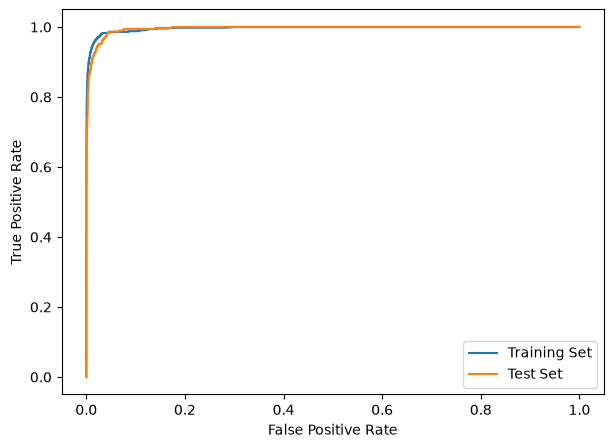

,Training Set,Test Set
AUC,0.996250,0.995385
Misclassification Rate,0.004583,0.008625


In [9]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
y_train_xgb = (y_train == "pos").astype(int)
y_test_xgb = (y_test == "pos").astype(int)
xgb = XGBClassifier(
    objective = "binary:logistic",
    eval_metric = "logloss",
    n_estimators = 100,
    max_depth = 3,
    learning_rate = 0.1,
    tree_method = "hist",
    random_state = 42,
    n_jobs = 1
)
param_grid = {
    "reg_alpha": [0, 0.01, 0.1, 1]
}
grid_search = GridSearchCV(
    estimator = xgb,
    param_grid = param_grid,
    cv = 5,
    scoring = "accuracy",
    n_jobs = -1
)
grid_search.fit(X_train_imputed, y_train_xgb)
xgb_best = grid_search.best_estimator_

print("Best alpha:", grid_search.best_params_["reg_alpha"])
print("5-fold CV error:", 1 - grid_search.best_score_)

train_predxgb = xgb_best.predict(X_train_imputed)
test_predxgb = xgb_best.predict(X_test_imputed)
train_probxgb = xgb_best.predict_proba(X_train_imputed)[:, 1]
test_probxgb = xgb_best.predict_proba(X_test_imputed)[:, 1]
train_cmxgb = confusion_matrix(y_train_xgb, train_predxgb)
test_cmxgb = confusion_matrix(y_test_xgb, test_predxgb)

print("Training Confusion Matrix")
display(pd.DataFrame(
    train_cmxgb,
    index = ["Actual neg", "Actual pos"],
    columns = ["Predicted neg", "Predicted pos"]
))
print("Test Confusion Matrix")
display(pd.DataFrame(
    test_cmxgb,
    index = ["Actual neg", "Actual pos"],
    columns = ["Predicted neg", "Predicted pos"]
))
train_fpr_xgb, train_tpr_xgb, _ = roc_curve(y_train_xgb, train_probxgb)
test_fpr_xgb, test_tpr_xgb, _ = roc_curve(y_test_xgb, test_probxgb)

plt.figure(figsize = (7, 5))
plt.plot(train_fpr_xgb, train_tpr_xgb, label = "Training Set")
plt.plot(test_fpr_xgb, test_tpr_xgb, label = "Test Set")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

train_auc_xgb = roc_auc_score(y_train_xgb, train_probxgb)
test_auc_xgb = roc_auc_score(y_test_xgb, test_probxgb)
train_error_xgb = 1 - accuracy_score(y_train_xgb, train_predxgb)
test_error_xgb = 1 - accuracy_score(y_test_xgb, test_predxgb)
pd.DataFrame({
    "Training Set": [train_auc_xgb, train_error_xgb],
    "Test Set": [test_auc_xgb, test_error_xgb]
}, index = ["AUC", "Misclassification Rate"])

### 1.(f)

Best alpha: 0.01
5-fold CV error: 0.02028333333333321
Training Confusion Matrix


,Predicted neg,Predicted pos
Actual neg,57923,1077
Actual pos,72,928


Test Confusion Matrix


,Predicted neg,Predicted pos
Actual neg,15359,266
Actual pos,28,347


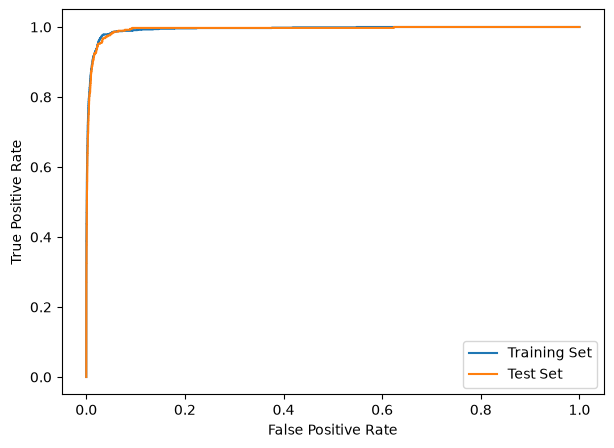

,Training Set,Test Set
AUC,0.993707,0.993073
Misclassification Rate,0.019150,0.018375


In [10]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
smote_xgb_pipeline = Pipeline([
    ("smote", SMOTE(random_state = 42)),
    ("xgb", XGBClassifier(
        objective = "binary:logistic",
        eval_metric = "logloss",
        n_estimators = 100,
        max_depth = 3,
        learning_rate = 0.1,
        tree_method = "hist",
        random_state = 42,
        n_jobs = 1
    ))
])
param_grid_smote = {
    "xgb__reg_alpha": [0, 0.01, 0.1, 1]
}
grid_search_smote = GridSearchCV(
    estimator = smote_xgb_pipeline,
    param_grid = param_grid_smote,
    cv = 5,
    scoring = "accuracy",
    n_jobs = -1
)
grid_search_smote.fit(X_train_imputed, y_train_xgb)
smote_xgb_best = grid_search_smote.best_estimator_

print("Best alpha:", grid_search_smote.best_params_["xgb__reg_alpha"])
print("5-fold CV error:", 1 - grid_search_smote.best_score_)

train_predsmote = smote_xgb_best.predict(X_train_imputed)
test_predsmote = smote_xgb_best.predict(X_test_imputed)
train_probsmote = smote_xgb_best.predict_proba(X_train_imputed)[:, 1]
test_probsmote = smote_xgb_best.predict_proba(X_test_imputed)[:, 1]
train_cmsmote = confusion_matrix(y_train_xgb, train_predsmote)
test_cmsmote = confusion_matrix(y_test_xgb, test_predsmote)

print("Training Confusion Matrix")
display(pd.DataFrame(
    train_cmsmote,
    index = ["Actual neg", "Actual pos"],
    columns = ["Predicted neg", "Predicted pos"]
))
print("Test Confusion Matrix")
display(pd.DataFrame(
    test_cmsmote,
    index = ["Actual neg", "Actual pos"],
    columns = ["Predicted neg", "Predicted pos"]
))

train_fpr_smote, train_tpr_smote, _ = roc_curve(
    y_train_xgb, train_probsmote
)
test_fpr_smote, test_tpr_smote, _ = roc_curve(
    y_test_xgb, test_probsmote
)

plt.figure(figsize = (7, 5))
plt.plot(train_fpr_smote, train_tpr_smote, label = "Training Set")
plt.plot(test_fpr_smote, test_tpr_smote, label = "Test Set")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

train_aucsmote = roc_auc_score(y_train_xgb, train_probsmote)
test_aucsmote = roc_auc_score(y_test_xgb, test_probsmote)
train_errorsmote = 1 - accuracy_score(y_train_xgb, train_predsmote)
test_errorsmote = 1 - accuracy_score(y_test_xgb, test_predsmote)
pd.DataFrame({
    "Training Set": [train_aucsmote, train_errorsmote],
    "Test Set": [test_aucsmote, test_errorsmote]
}, index = ["AUC", "Misclassification Rate"])

## 6.6.3
##### (a) iv: Training RSS is non-increasing because every solution feasible at a smaller $s$ remains feasible at a larger $s$.
##### (b) ii: Test RSS can first decrease as underfitting is reduced and later increase from overfitting. This is a typical bias–variance pattern, not a mathematical guarantee for every dataset.
##### (c) iii: Variance generally increases as the fit becomes more flexible.
##### (d) iv: Squared bias generally decreases with increasing flexibility.
##### (e) v: Irreducible error is independent of the chosen model.

## 6.6.5
Let $z_i=x_{i1}=x_{i2}$ and $t=\beta_1+\beta_2$.
##### (a) Ridge minimizes $\sum_{i=1}^2(y_i-z_i(\beta_1+\beta_2))^2+\lambda(\beta_1^2+\beta_2^2)$.
##### (b) For fixed $t$, $\beta_1^2+\beta_2^2=t^2/2+(\beta_1-\beta_2)^2/2$, minimized uniquely by $\beta_1=\beta_2=t/2$ for $\lambda>0$. Thus ridge assigns equal coefficients.
##### (c) Lasso minimizes $\sum_{i=1}^2(y_i-z_i(\beta_1+\beta_2))^2+\lambda(|\beta_1|+|\beta_2|)$.
##### (d) For a fixed optimal nonzero sum $t$, any same-sign pair $\beta_1+\beta_2=t$ has the same $|\beta_1|+|\beta_2|=|t|$. There are infinitely many solutions, including $(t,0)$ and $(0,t)$. But there is an exception that if the optimal sum is zero, the unique penalized solution is $(0,0)$; therefore non-uniqueness is not unconditional for every possible $\lambda$.

## 8.4.5
##### -The ten estimated red-class probabilities are 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.
##### -Majority vote: Six trees predict Red (probability > 0.5), and four predict Green, so the result is Red.
##### -Average probability: The mean is 0.45, below 0.5, so the result is Green.

## 9.7.3

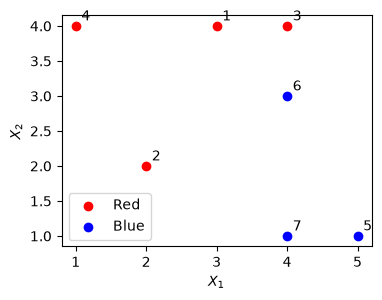

In [11]:
red_x1 = [3, 2, 4, 1]
red_x2 = [4, 2, 4, 4]
blue_x1 = [5, 4, 4]
blue_x2 = [1, 3, 1]

plt.figure(figsize = (4, 3))
plt.scatter(red_x1, red_x2, color = "red", label = "Red")
plt.scatter(blue_x1, blue_x2, color = "blue", label = "Blue")
for i, (x1, x2) in enumerate(
    zip(red_x1 + blue_x1, red_x2 + blue_x2),
    start = 1
):
    plt.text(x1 + 0.08, x2 + 0.08, str(i))
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend()
plt.show()

##### -The solid line is the optimal separating hyperplane, given numerically by the fitted $\beta_0+\beta_1X_1+\beta_2X_2=0$.
##### -Classify Red when $\beta_0+\beta_1X_1+\beta_2X_2>0$, Blue otherwise; the fitted coefficients are printed above.
##### -The dashed parallel lines mark the margins, $\beta_0+\beta^TX=\pm1$.

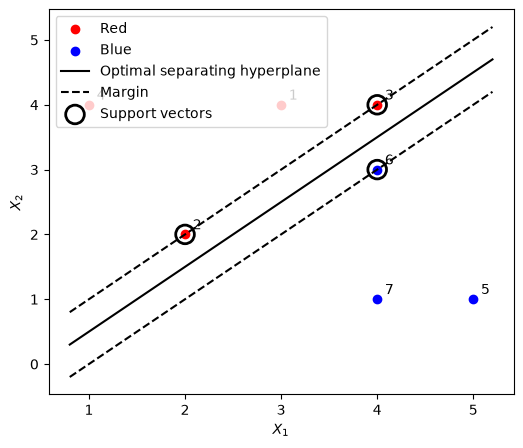

In [12]:
x_values = [0.8, 5.2]
plt.figure(figsize = (6, 5))
plt.scatter(red_x1, red_x2, color = "red", label = "Red")
plt.scatter(blue_x1, blue_x2, color = "blue", label = "Blue")
for i, (x1, x2) in enumerate(
    zip(red_x1 + blue_x1, red_x2 + blue_x2),
    start = 1
):
    plt.text(x1 + 0.08, x2 + 0.08, str(i))
plt.plot(
    x_values,
    [x - 0.5 for x in x_values],
    color = "black",
    label = "Optimal separating hyperplane"
)
plt.plot(
    x_values,
    x_values,
    color = "black",
    linestyle = "--",
    label = "Margin"
)
plt.plot(
    x_values,
    [x - 1 for x in x_values],
    color = "black",
    linestyle = "--"
)
plt.scatter(
    [2, 4, 4],
    [2, 4, 3],
    facecolors = "none",
    edgecolors = "black",
    s = 180,
    linewidths = 2,
    label = "Support vectors"
)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend()
plt.show()

##### -The circled points are the support vectors; their observation indices are printed above.
##### -Observation 7 is not a support vector. A sufficiently small movement that does not change the active constraints will leave the maximum-margin line unchanged.

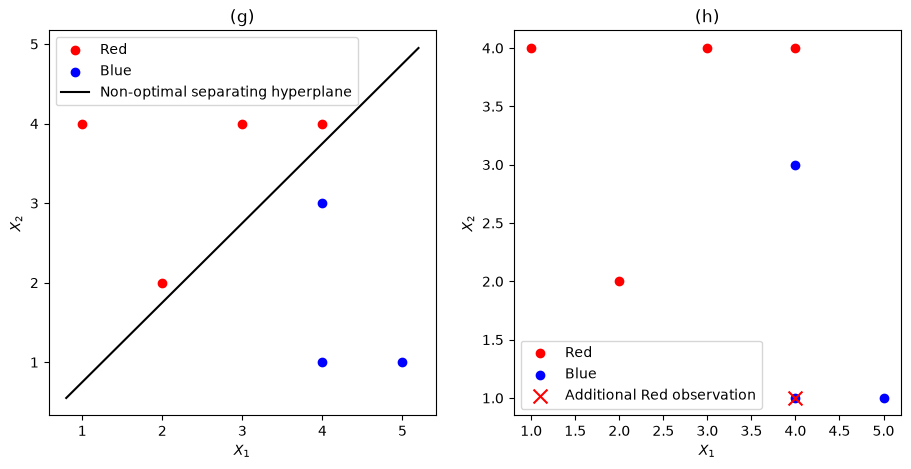

In [13]:
x_values = [0.8, 5.2]
fig, axes = plt.subplots(1, 2, figsize = (11, 5))
axes[0].scatter(red_x1, red_x2, color = "red", label = "Red")
axes[0].scatter(blue_x1, blue_x2, color = "blue", label = "Blue")
axes[0].plot(
    x_values,
    [x - 0.25 for x in x_values],
    color = "black",
    label = "Non-optimal separating hyperplane"
)
axes[0].set_xlabel("$X_1$")
axes[0].set_ylabel("$X_2$")
axes[0].set_title("(g)")
axes[0].legend()
axes[1].scatter(red_x1, red_x2, color = "red", label = "Red")
axes[1].scatter(blue_x1, blue_x2, color = "blue", label = "Blue")
axes[1].scatter(
    4,
    1,
    color = "red",
    marker = "x",
    s = 100,
    label = "Additional Red observation"
)
axes[1].set_xlabel("$X_1$")
axes[1].set_ylabel("$X_2$")
axes[1].set_title("(h)")
axes[1].legend()
plt.show()

##### -One nonoptimal separating hyperplane can be illustrated by shifting/rotating a valid separator slightly while checking all seven labels remain correct.
##### -Add a Blue point at exactly (3,4), the location of an existing Red point. Since identical feature vectors cannot receive different labels under a deterministic hyperplane, the classes are no longer linearly separable.